In [1]:
%pip install ultralytics opencv-python pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import cv2
import ultralytics

print("YOLO:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

YOLO: 8.4.183
OpenCV: 4.14.0
PyTorch: 2.14.1+cpu
CUDA available: False
Running on CPU


In [3]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("AutoVision model loaded successfully!")

AutoVision model loaded successfully!


In [4]:
from pathlib import Path
from IPython.display import Video, display

video_path = Path( r"C:\Users\goushik lap\traffic.mp4.mp4")

assert video_path.exists(), (
    f"Video not found: {video_path.resolve()}"
)

results = model.predict(
    source=str(video_path),
    classes=[2, 3, 5, 7],  # car, motorcycle, bus, truck
    conf=0.35,
    imgsz=640,
    save=True,
    project="runs",
    name="autovision",
    exist_ok=True,
    verbose=False
)

print("Detection complete!")
print("Output folder:", Path("runs/autovision").resolve())

WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to C:\Users\goushik lap\runs\detect\runs\autovision
Detection complete!
Output folder: C:\Users\goushik lap\runs\autovision


In [5]:
output_video = Path("runs/autovision/traffic.avi")

if output_video.exists():
    display(Video(str(output_video), embed=True))
else:
    print("Check the output folder for the generated video filename.")

Check the output folder for the generated video filename.


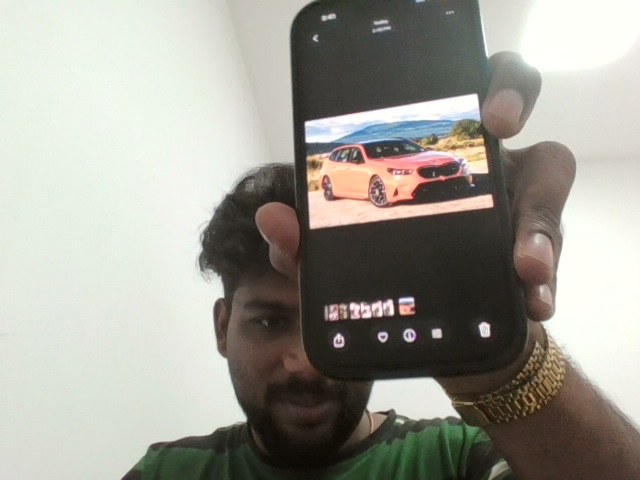

In [ ]:
import cv2
import time
from IPython.display import display, clear_output, Image

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError(
        "Webcam unavailable. Close other camera apps and check permissions."
    )

try:
    for _ in range(300):  # Maximum 300 frames
        ok, frame = cap.read()

        if not ok:
            break

        result = model.track(
            frame,
            persist=True,
            classes=[2, 3, 5, 7],
            conf=0.35,
            imgsz=640,
            verbose=False
        )[0]

        annotated = result.plot()
        annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        clear_output(wait=True)
        display(Image(data=cv2.imencode(
            ".jpg", cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR)
        )[1].tobytes()))

except KeyboardInterrupt:
    print("Webcam stopped.")

finally:
    cap.release()

In [1]:
import os
import sys

print("Python:", sys.version)
print("Working folder:", os.getcwd())

video_path = r"C:\Users\goushik lap\traffic.mp4.mp4"
print("Video exists:", os.path.exists(video_path))

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Working folder: C:\Users\goushik lap
Video exists: True


In [2]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
print("YOLO model loaded successfully!")

YOLO model loaded successfully!


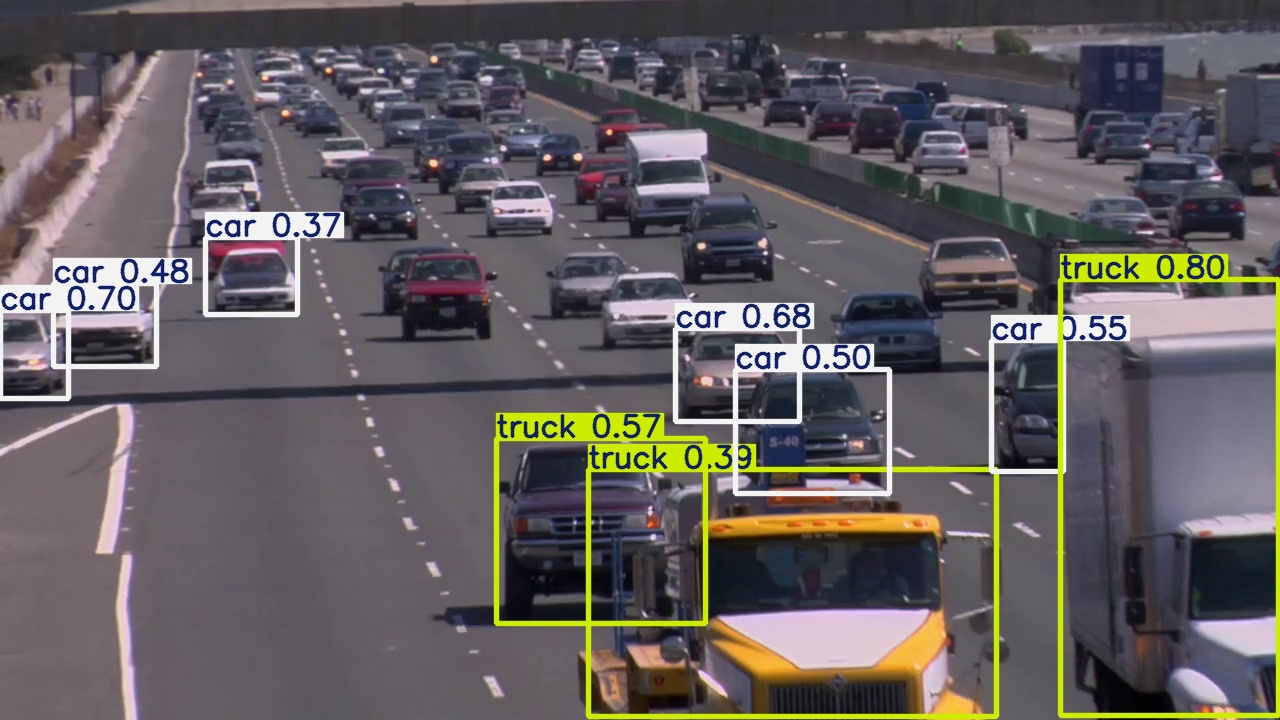

Vehicle detection test completed!


In [3]:
import cv2
from IPython.display import display, Image

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Could not open the video.")

ret, frame = cap.read()
cap.release()

if ret:
    result = model.predict(
        source=frame,
        imgsz=416,
        conf=0.35,
        device="cpu",
        verbose=False
    )[0]

    display(Image(data=cv2.imencode(".jpg", result.plot())[1].tobytes()))
    print("Vehicle detection test completed!")
else:
    print("Could not read a frame from the video.")

In [4]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
print("YOLO model loaded successfully!")

YOLO model loaded successfully!


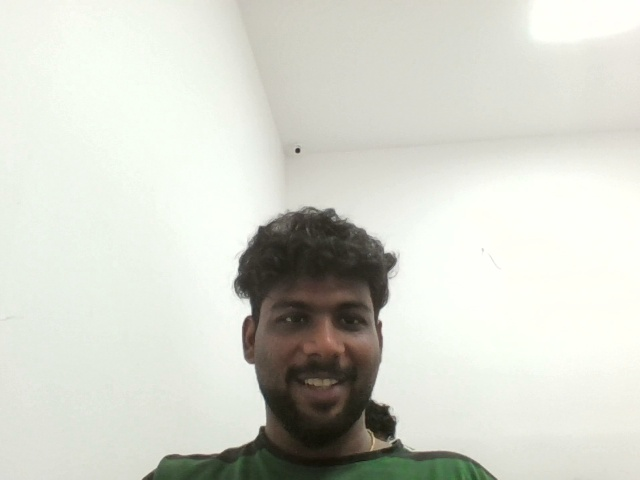

Live vehicle detection running — interrupt the cell to stop.


KeyboardInterrupt: 

In [5]:
import cv2
import time
from IPython.display import display, clear_output, Image

# COCO vehicle classes: car, motorcycle, bus, truck
vehicle_classes = [2, 3, 5, 7]

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)  # Windows webcam

if not cap.isOpened():
    cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Webcam not found. Close apps using your camera and try again.")

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Could not read webcam frame.")
            break

        # Smaller inference size and CPU mode for stability
        result = model.predict(
            source=frame,
            imgsz=416,
            conf=0.35,
            classes=vehicle_classes,
            device="cpu",
            verbose=False
        )[0]

        annotated_frame = result.plot()
        success, buffer = cv2.imencode(".jpg", annotated_frame)

        if success:
            clear_output(wait=True)
            display(Image(data=buffer.tobytes()))
            print("Live vehicle detection running — interrupt the cell to stop.")

        time.sleep(0.03)

finally:
    cap.release()
    cv2.destroyAllWindows()